# Preprocessing — PBL Klasifikasi (SVM, kNN, Naive Bayes)

**Kelompok PBL — Klasifikasi Harga Properti**

Notebook ini dijalankan **SEKALI** untuk menghasilkan data siap pakai (`data_preprocessed.csv`)
yang akan dipakai oleh semua notebook klasifikasi (kNN, SVM, Naive Bayes),
sehingga preprocessing **identik** di semua metode (fair comparison).

Preprocessing mengikuti **langkah yang sama persis** dengan tugas clustering sebelumnya (UTS),
ditambah pembuatan label kelas dari kolom `harga`.

**Dataset:** `../UTS/properti_multi_kota.csv`

## 1. Load Data

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler

df = pd.read_csv('../UTS/properti_multi_kota.csv')
print("Shape awal:", df.shape)
df.head()

Shape awal: (64650, 8)


,sumber,lokasi,luas_m2,luas_bangunan,jumlah_kamar,jumlah_kamar_mandi,usia_bangunan,harga
0,uas-properti/Jabodetabek,Tangerang,30.0,NaN,3.0,3.0,33.0,2.037543e+08
1,uas-properti/Jabodetabek,Bekasi,122.0,NaN,5.0,4.0,19.0,1.058032e+09
2,uas-properti/Jabodetabek,Bekasi,142.8,NaN,1.0,1.0,9.0,1.335793e+09
3,uas-properti/Jabodetabek,Bekasi,152.6,NaN,4.0,3.0,6.0,1.613771e+09
4,uas-properti/Jabodetabek,Depok,61.2,NaN,1.0,1.0,9.0,5.221562e+08


## 2. Preprocessing Universal (sama dengan UTS)

Langkah: hapus duplikat → hapus outlier/nilai tidak wajar → konversi tahun→usia bangunan →
isi missing value dengan median → sampling 15.000 (random_state=42).

In [2]:
# ============================================
# PREPROCESSING UNIVERSAL - sama dengan UTS
# ============================================

# 1. Hapus duplikat (hasil scraping dari banyak sumber)
before = len(df)
df = df.drop_duplicates()
print(f"[1] Hapus duplikat       : {before} -> {len(df)}")

# 2. Hapus outlier & nilai tidak wajar (error scraping)
before = len(df)
df = df[(df['luas_m2'] >= 10) & (df['luas_m2'] <= 2000)]
df = df[(df['luas_bangunan'].isna()) |
        ((df['luas_bangunan'] >= 10) & (df['luas_bangunan'] <= 2000))]
df = df[(df['harga'] >= 50_000_000) & (df['harga'] <= 100_000_000_000)]
df = df[df['jumlah_kamar'].isna() | (df['jumlah_kamar'] <= 20)]
df = df[df['jumlah_kamar_mandi'].isna() | (df['jumlah_kamar_mandi'] <= 20)]
print(f"[2] Hapus outlier        : {before} -> {len(df)}")

# 3. Perbaiki usia_bangunan: sebagian sumber menyimpan TAHUN bangunan
#    (misal 2020), bukan usia. Nilai > 100 dikonversi: usia = 2026 - tahun.
mask_tahun = df['usia_bangunan'] > 100
df.loc[mask_tahun, 'usia_bangunan'] = 2026 - df.loc[mask_tahun, 'usia_bangunan']
df.loc[~df['usia_bangunan'].between(0, 100) & df['usia_bangunan'].notna(),
       'usia_bangunan'] = np.nan
print(f"[3] Konversi tahun->usia : {mask_tahun.sum()} baris dikonversi")

# 4. Isi missing values dengan median
FEATURES = ['luas_m2', 'luas_bangunan', 'jumlah_kamar',
            'jumlah_kamar_mandi', 'usia_bangunan', 'harga']
for col in FEATURES:
    df[col] = df[col].fillna(df[col].median())
print(f"[4] Missing values diisi : {df[FEATURES].isnull().sum().sum()} tersisa")

# 5. Sampling 15.000 data (reproducible) - sama dengan UTS
df = df.sample(n=15000, random_state=42).reset_index(drop=True)
print(f"[5] Sampling             : 15.000 data (random_state=42)")

[1] Hapus duplikat       : 64650 -> 57494
[2] Hapus outlier        : 57494 -> 56170
[3] Konversi tahun->usia : 2757 baris dikonversi
[4] Missing values diisi : 0 tersisa
[5] Sampling             : 15.000 data (random_state=42)


## 3. Pembuatan Label Kelas (target klasifikasi)

Label diturunkan dari kolom `harga` menggunakan **pembagian tertile (3 kelas seimbang)**:

- **Murah** : harga < kuantil 1/3
- **Sedang**: kuantil 1/3 – 2/3
- **Mahal** : harga > kuantil 2/3

Setelah label dibuat, kolom `harga` **dikeluarkan dari fitur** agar tidak bocor (data leakage).

In [3]:
# Batas kelas dari kuantil harga
q1 = df['harga'].quantile(1/3)
q2 = df['harga'].quantile(2/3)
print(f"Batas Murah  : < Rp {q1:,.0f}")
print(f"Batas Sedang : Rp {q1:,.0f} - Rp {q2:,.0f}")
print(f"Batas Mahal  : > Rp {q2:,.0f}")

def buat_label(harga):
    if harga < q1:
        return 'Murah'
    elif harga <= q2:
        return 'Sedang'
    return 'Mahal'

df['kelas_harga'] = df['harga'].apply(buat_label)
print()
print("Distribusi kelas:")
print(df['kelas_harga'].value_counts())

Batas Murah  : < Rp 480,000,000
Batas Sedang : Rp 480,000,000 - Rp 1,220,000,000
Batas Mahal  : > Rp 1,220,000,000

Distribusi kelas:
kelas_harga
Sedang    5020
Mahal     4999
Murah     4981
Name: count, dtype: int64


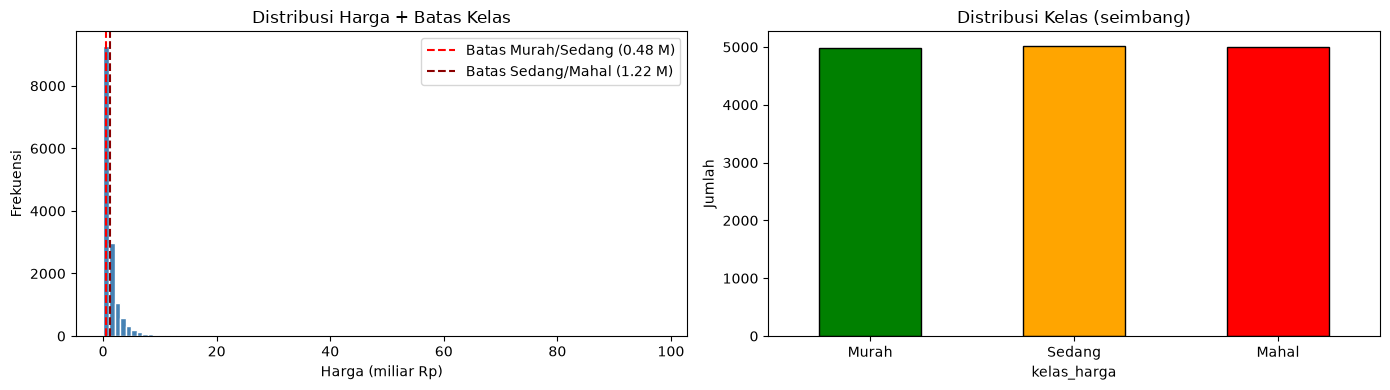

In [4]:
# Visualisasi distribusi harga dan batas kelas
fig, ax = plt.subplots(1, 2, figsize=(14, 4))

ax[0].hist(df['harga'] / 1e9, bins=100, color='steelblue', edgecolor='white')
ax[0].axvline(q1 / 1e9, color='red', linestyle='--', label=f'Batas Murah/Sedang ({q1/1e9:.2f} M)')
ax[0].axvline(q2 / 1e9, color='darkred', linestyle='--', label=f'Batas Sedang/Mahal ({q2/1e9:.2f} M)')
ax[0].set_xlabel('Harga (miliar Rp)')
ax[0].set_ylabel('Frekuensi')
ax[0].set_title('Distribusi Harga + Batas Kelas')
ax[0].legend()

df['kelas_harga'].value_counts().reindex(['Murah', 'Sedang', 'Mahal']).plot(
    kind='bar', ax=ax[1], color=['green', 'orange', 'red'], edgecolor='black')
ax[1].set_title('Distribusi Kelas (seimbang)')
ax[1].set_ylabel('Jumlah')
ax[1].set_xticklabels(['Murah', 'Sedang', 'Mahal'], rotation=0)
plt.tight_layout()
plt.show()

## 4. Scaling & Simpan Data

Fitur yang dipakai (tanpa `harga` karena sudah menjadi label): `luas_m2`, `luas_bangunan`,
`jumlah_kamar`, `jumlah_kamar_mandi`, `usia_bangunan`. Scaling dengan **StandardScaler**
(penting untuk kNN & SVM yang berbasis jarak).

In [5]:
# 6. Scaling (StandardScaler)
FEATURES = ['luas_m2', 'luas_bangunan', 'jumlah_kamar',
            'jumlah_kamar_mandi', 'usia_bangunan']
X = df[FEATURES].copy()
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

df_out = pd.DataFrame(X_scaled, columns=FEATURES)
df_out['kelas_harga'] = df['kelas_harga'].values

print(f"[6] Data siap klasifikasi: {df_out.shape}")
print(f"[7] Fitur                : {FEATURES}")
print(f"[8] Label                : kelas_harga (Murah/Sedang/Mahal)")
df_out.head()

[6] Data siap klasifikasi: (15000, 6)
[7] Fitur                : ['luas_m2', 'luas_bangunan', 'jumlah_kamar', 'jumlah_kamar_mandi', 'usia_bangunan']
[8] Label                : kelas_harga (Murah/Sedang/Mahal)


,luas_m2,luas_bangunan,jumlah_kamar,jumlah_kamar_mandi,usia_bangunan,kelas_harga
0,-0.204960,-0.008406,0.197443,0.803270,-0.08498,Mahal
1,-0.204960,-0.339810,-0.443051,0.803270,-0.08498,Sedang
2,-0.402575,-0.360964,0.197443,0.062383,-0.08498,Sedang
3,-0.195550,-0.537243,-0.443051,-0.678505,-0.08498,Sedang
4,-0.487267,-0.375066,-1.724040,-0.678505,-0.08498,Murah


In [6]:
# Simpan data hasil preprocessing
df_out.to_csv('data_preprocessed.csv', index=False)
print("Tersimpan: data_preprocessed.csv")

# Simpan juga versi tanpa scaling (untuk keperluan analisis/Naive Bayes jika diperlukan)
df_raw = df[FEATURES].copy()
df_raw['kelas_harga'] = df['kelas_harga'].values
df_raw.to_csv('data_preprocessed_raw.csv', index=False)
print("Tersimpan: data_preprocessed_raw.csv (tanpa scaling)")

Tersimpan: data_preprocessed.csv
Tersimpan: data_preprocessed_raw.csv (tanpa scaling)


## Ringkasan

- **Data awal:** 64.650 baris → setelah cleaning: 56.170 → **sampling 15.000** (random_state=42, sama dengan UTS)
- **Batas kelas:** Murah < Rp 480 juta | Sedang Rp 480 juta – 1,22 miliar | Mahal > Rp 1,22 miliar
- **Distribusi kelas seimbang:** Murah 4.981 | Sedang 5.020 | Mahal 4.999
- **Fitur (5, ter-scaling StandardScaler):** luas_m2, luas_bangunan, jumlah_kamar, jumlah_kamar_mandi, usia_bangunan
- **Label:** `kelas_harga` (3 kelas); kolom `harga` dikeluarkan dari fitur untuk mencegah data leakage
- **Output:** `data_preprocessed.csv` (ter-scaling, dipakai semua metode) & `data_preprocessed_raw.csv` (tanpa scaling)

Semua notebook klasifikasi (kNN, SVM, Naive Bayes) menggunakan file CSV ini — preprocessing identik, perbandingan fair.